In [ ]:
# Used Claude Code to help plot the figures against noise

# Measurement-noise tables and figures

## Purpose

This notebook regenerates the measurement-noise tables and figures used in the final report from saved NPZ results. It does not run any inversions.

| Source | Levels | Runs at each level |
|---|---|---|
| *measurement-noise-sweep.npz* | \(0\%\), \(0.25\%\), \(0.5\%\), \(0.75\%\), \(1\%\) | Five noise draws from one start; one run at \(0\%\) |
| *measurement-noise-sweep-2-4pc.npz* | \(0\%\), \(2\%\), \(3\%\), \(4\%\) | Five noise draws from the same start; shared \(0\%\) control |
| *limb-geometry-run{1..5}.npz* | \(5\%\) | Five starts using one noise draw |

The \(5\%\) results appear in the tables but not the noise-trend figures because their spread is over starting points rather than noise draws. Figures use the realised electrode-level error \(\eta_{\mathcal M}\), not the full-volume percentage passed to add_measurement_noise; *noise-conversion.ipynb* explains this conversion. muscle_L is unavailable in the saved \(5\%\) geometry files and is shown as missing rather than inferred.

In [1]:
# One thread, set before torch is imported.
#
# The clean field solved below has to be the field the sweeps and the ensemble added
# their noise to, bit for bit: this notebook re-derives what those runs saw, and a
# field differing in the last few bits gives a conversion factor for a slightly
# different experiment. All three sources solved it under `torch.set_num_threads(1)`,
# and a threaded reduction sums in whatever order the threads finish in.
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import math
import platform
from pathlib import Path

import matplotlib.patheffects as path_effects
import matplotlib.pyplot as plt
import numpy as np
import scipy
import torch
from matplotlib.ticker import (
    FixedLocator,
    FuncFormatter,
    LogLocator,
    NullFormatter,
    NullLocator,
)

import neuralphysics
from neuralphysics import (
    LIMB,
    SOURCE_SPECS,
    CoefficientHierarchy,
    ElectrodeArray,
    add_measurement_noise,
    configure,
    forward,
    gaussian_dipole,
    grid_at,
    parameter_names,
    thicknesses,
    viz,
)
from neuralphysics.viz import PARAM_STYLE, TISSUE_COLOURS

In [2]:
print(configure())
torch.set_num_threads(1)

print(f"neuralphysics {neuralphysics.__version__} | torch {torch.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | python {platform.python_version()}")
print(f"default dtype {torch.get_default_dtype()} | torch threads {torch.get_num_threads()} | "
      f"{platform.platform()}")

{'dtype': 'torch.float64', 'seed': 42}
neuralphysics 0.1.0 | torch 2.5.1 | numpy 1.26.4 | scipy 1.17.1 | python 3.11.15
default dtype torch.float64 | torch threads 1 | macOS-26.6.1-arm64-arm-64bit


## Experiment settings

These constants match the notebooks that generated the saved results.

In [3]:
N = 65          # nodes per axis; N = 2^k + 1 must hold for the v-cycle to work
NUM_CYCLES = 8  # fixed budget - not a convergence tolerance
WIDTH = 0.05    # the 1/e blob radius of a source, a physical length

LIMB_RADIUS_MM = 24.0                # the physical limb radius, at r/R = 0.5
MM_PER_UNIT = LIMB_RADIUS_MM / 0.5   # normalised radius -> millimetres

SWEEP_RUN = 1   # the ensemble starting point both sweeps ran from; caption only

RESULTS = Path("..") / "experiment-results"   # where the report picks the outputs up

## Noise levels and seeds

The original seed scheme is reused so the reconstructed noise fields match those supplied to the inversions.

In [4]:
LEVELS_SWEEP_LOW = (0.25, 0.5, 0.75, 1.0)     # measurement-noise-sweep.npz
LEVELS_SWEEP_HIGH = (2.0, 3.0, 4.0)           # measurement-noise-sweep-2-4pc.npz
LEVEL_ENSEMBLE = 5.0                          # limb-geometry-run{1..5}.npz
CONTROL = 0.0                                 # the noise-free run both sweeps share

LEVELS = (CONTROL,) + LEVELS_SWEEP_LOW + LEVELS_SWEEP_HIGH + (LEVEL_ENSEMBLE,)

SWEEP_DRAWS = (0, 1, 2, 3, 4)     # draw bases, per level, in both sweeps
ENSEMBLE_DRAW = (0,)              # the one realisation the ensemble inverted


def draws_for(percent):
    """The noise draws made at `percent`, as the experiments made them.

    The control draws nothing - adding a zero draw to the clean field gives the clean
    field, whatever the seed - and the ensemble drew once and varied its start
    instead, so neither has five.
    """
    if percent == CONTROL:
        return ()
    return ENSEMBLE_DRAW if percent == LEVEL_ENSEMBLE else SWEEP_DRAWS


print(f"{len(LEVELS)} levels: " + ", ".join(f"{p:g}%" for p in LEVELS))

9 levels: 0%, 0.25%, 0.5%, 0.75%, 1%, 2%, 3%, 4%, 5%


## Electrode-level noise

The clean fields are solved once and reused. For the two sources together,

\[
\eta_{\mathcal M}=
\sqrt{\frac{\sum_k\lVert\mathrm{noise}_k\rVert_{\mathcal M}^2}
{\sum_k\lVert\phi_k\rVert_{\mathcal M}^2}}.
\]

Stacking the source vectors matches the residual used by the inverse objective.

In [5]:
grid = grid_at(N)

sources = [gaussian_dipole(grid, LIMB, width=WIDTH, r_blob_norm=r_norm, angle_deg=angle)
           for r_norm, angle in SOURCE_SPECS]

coeff_true = CoefficientHierarchy.from_vectors(LIMB, N)
phi_clean = [forward(I, coeff_true, num_cycles=NUM_CYCLES) for I in sources]

mask_nodes = ElectrodeArray().mask(N)   # full coverage of the four lateral faces


def eta_measured(percent, draw):
    """Realised electrode-level relative error of one draw at one nominal level."""
    if percent == CONTROL:
        return 0.0                     # no draw is made; the control is the clean field

    noise_sq, signal_sq = 0.0, 0.0
    for s, phi in enumerate(phi_clean):
        phi_obs, _ = add_measurement_noise(phi, percent, len(phi_clean) * draw + s)
        noise_sq += float((phi_obs - phi)[mask_nodes].pow(2).sum())
        signal_sq += float(phi[mask_nodes].pow(2).sum())
    return math.sqrt(noise_sq / signal_sq)


# one figure per level: the mean over the draws made at it, which at 5% is the single
# draw the ensemble inverted and not an expectation over draws it never saw
ETA_M = {percent: float(np.mean([eta_measured(percent, draw)
                                 for draw in draws_for(percent)] or [0.0]))
         for percent in LEVELS}

K = math.sqrt(sum(float(phi.pow(2).mean()) for phi in phi_clean)
              / sum(float(phi[mask_nodes].pow(2).mean()) for phi in phi_clean))

print(f"K = {K:.4f}\n")
print(f"{'η_vol (%)':>10} {'η_M (%)':>9} {'draws':>7}")
for percent in LEVELS:
    print(f"{percent:>10.2f} {100 * ETA_M[percent]:>9.2f} {len(draws_for(percent)):>7}")

K = 1.8718

 η_vol (%)   η_M (%)   draws
      0.00      0.00       0
      0.25      0.47       5
      0.50      0.93       5
      0.75      1.40       5
      1.00      1.87       5
      2.00      3.74       5
      3.00      5.60       5
      4.00      7.47       5
      5.00      9.31       1


## Recovered parameters

The loaders convert each saved experiment to one (runs, quantity) array per level. Relative errors are computed per run and then averaged. The single control run is not duplicated to match the five-draw arrays.

In [6]:
QUANTITY_NAMES = ([f"{nm} (S/m)" for nm in parameter_names(LIMB)]
                  + [f"{nm} (mm)" for nm in LIMB.layer_names[:-1]])
N_SIGMA = len(parameter_names(LIMB))
IS_SIGMA = torch.tensor([q.endswith("(S/m)") for q in QUANTITY_NAMES])
DECIMALS = [".4f"] * N_SIGMA + [".2f"] * (len(QUANTITY_NAMES) - N_SIGMA)
BONE = QUANTITY_NAMES.index("bone (S/m)")
MUSCLE_L = QUANTITY_NAMES.index("muscle_L (S/m)")


def load_sweep(path):
    """A saved sweep as {level: (runs, quantity)}, plus the reference it was scored on.

    The npz is flat and keyed by (noise, draw), so it is grouped back rather than
    reshaped - the draw axis is ragged and was never padded.
    """
    d = np.load(path, allow_pickle=True)
    if [str(q) for q in d["quantity_names"]] != QUANTITY_NAMES:
        raise ValueError(f"{path.name} was saved against different quantities")

    percents = [float(p) for p in d["noise_percent"]]
    quantity = torch.as_tensor(d["quantity"])
    levels = {p: quantity[[i for i, q in enumerate(percents) if q == p]]
              for p in sorted(set(percents))}
    return levels, torch.as_tensor(d["reference"])


def load_ensemble(stem, n_runs=5):
    """The 5% ensemble as one (runs, quantity) tensor, with muscle_L nan.

    Each file is a geometry *history* - every iterate of one run - so the recovered
    parameters are its last row, which is the point the run stopped at.

    A history carries `sigma_T`, one transverse conductivity per layer, so four of the
    five conductivities are here and the longitudinal muscle conductivity is not. It
    is filled with nan rather than dropped, so that the column keeps its place in
    every table and figure and every average over it is taken by a nan-aware
    reduction: a missing number that still occupies its slot cannot silently shift the
    quantity beside it.
    """
    # sigma_T is one entry per layer, in LIMB.layer_names order; the parameter vector
    # names those entries as the transverse component of each layer
    columns = [QUANTITY_NAMES.index(f"{nm}{'_T' if nm in LIMB.anisotropic_layers else ''} (S/m)")
               for nm in LIMB.layer_names]

    runs = []
    for k in range(1, n_runs + 1):
        d = np.load(RESULTS / f"{stem}{k}.npz")
        row = torch.full((len(QUANTITY_NAMES),), float("nan"), dtype=torch.float64)
        row[columns] = torch.as_tensor(d["sigma_T"][-1])
        row[N_SIGMA:] = thicknesses(torch.as_tensor(d["interfaces"][-1]),
                                    scale=MM_PER_UNIT)[:-1]
        runs.append(row)
    return torch.stack(runs)


low, reference = load_sweep(RESULTS / "measurement-noise-sweep.npz")
high, _ = load_sweep(RESULTS / "measurement-noise-sweep-2-4pc.npz")

# the control is one inversion saved in both files, so it is taken once
recovered = {**low, **{p: q for p, q in high.items() if p not in low},
             LEVEL_ENSEMBLE: load_ensemble("limb-geometry-run")}
recovered = {p: recovered[p] for p in LEVELS}

rel_error = {p: (q - reference).abs() / reference for p, q in recovered.items()}

print(f"{'η_vol (%)':>10} {'runs':>6} {'quantities':>11}   source")
for percent, q in recovered.items():
    source = ("both sweeps (control)" if percent == CONTROL else
              "ensemble, 5 starting points" if percent == LEVEL_ENSEMBLE else
              "sweep, 5 noise draws")
    print(f"{percent:>10.2f} {q.shape[0]:>6} "
          f"{int(torch.isfinite(q).all(0).sum()):>11}   {source}")

 η_vol (%)   runs  quantities   source
      0.00      1           8   both sweeps (control)
      0.25      5           8   sweep, 5 noise draws
      0.50      5           8   sweep, 5 noise draws
      0.75      5           8   sweep, 5 noise draws
      1.00      5           8   sweep, 5 noise draws
      2.00      5           8   sweep, 5 noise draws
      3.00      5           8   sweep, 5 noise draws
      4.00      5           8   sweep, 5 noise draws
      5.00      5           7   ensemble, 5 starting points


In [7]:
def spread(values):
    """Sample standard deviation down the run axis, nan where there is one run.

    The n - 1 correction, because the runs are a sample - of the noise realisations
    the generator could have produced, or of the starting points the ensemble could
    have drawn - and not the population. torch's own answer at a single sample is
    nan, which is the honest one: one run says nothing about spread.
    """
    if values.shape[0] > 1:
        return values.std(0, correction=1)
    return torch.full_like(values[0], float("nan"))


# per level, over the runs: one number per quantity
mean_recovered = torch.stack([recovered[p].mean(0) for p in LEVELS])
std_recovered = torch.stack([spread(recovered[p]) for p in LEVELS])
mean_error = torch.stack([rel_error[p].mean(0) for p in LEVELS])

# per level, over the quantities: one number per run, kept ragged because their
# spread is taken over runs. nanmean, so the 5% level averages the seven quantities
# it has rather than returning nan for all of them
per_run_all = [rel_error[p].nanmean(1) for p in LEVELS]
per_run_sigma = [rel_error[p][:, IS_SIGMA].nanmean(1) for p in LEVELS]
per_run_thick = [rel_error[p][:, ~IS_SIGMA].nanmean(1) for p in LEVELS]

N_QUANTITIES = [int(torch.isfinite(recovered[p]).all(0).sum()) for p in LEVELS]
N_RUNS = [recovered[p].shape[0] for p in LEVELS]
N_INVERSIONS = sum(N_RUNS)
I_CONTROL = LEVELS.index(CONTROL)
NOISY = [i for i, p in enumerate(LEVELS) if p != CONTROL]

# What the figures draw, and it is not every level. The tables report all nine; the
# figures draw the eight whose runs are noise draws from one starting point, because
# a curve through them is a statement about how the error grows with the noise and
# the ensemble level does not vary the noise. It is one level short of the tables by
# design - see the note above - and the tables are where its numbers are read.
DRAWN = [i for i in NOISY if LEVELS[i] != LEVEL_ENSEMBLE]

X_ETA = np.array([100 * ETA_M[LEVELS[i]] for i in DRAWN])   # the abscissa of every figure

print(f"{len(LEVELS)} levels, {N_INVERSIONS} inversions, "
      f"{len(QUANTITY_NAMES)} quantities")
print(f"noise-free floor, over the {len(QUANTITY_NAMES)} quantities: "
      f"{float(mean_error[I_CONTROL].nanmean()):.4%}")

9 levels, 41 inversions, 8 quantities
noise-free floor, over the 8 quantities: 0.0003%


## Tables

One formatting function supplies both the displayed values and saved table figures.

In [8]:
def as_number(value, spec):
    """A formatted number, or an em dash where there is no number.

    Two different absences print the same way, and both are absences: the spread of a
    single run is undefined, and muscle_L at 5% was never written to disk. A table
    that printed 0.0000 for either would be claiming a measurement that was not made.
    """
    v = float(value)
    return format(v, spec) if np.isfinite(v) else "—"


def as_percent(value):
    """The same, for a quantity carried as a fraction and read as a percentage.

    Two decimals, except where two decimals would print 0.00% for something that is
    not zero. The control run does not recover the truth - discretisation, the
    eight-cycle solve, the frozen diagonal and the limits of the parameterisation
    leave a few parts in a million - and that residue is the floor every noisy row is
    read against. Rounded to 0.00% it reads as a perfect recovery, which is a claim
    this experiment cannot make, and it makes `above floor` look like a copy of
    `rel err` rather than a subtraction. Below the point where two decimals resolve
    anything the number is given to two significant figures instead, which is the
    form the figures' floor annotation already takes: the table and the figure then
    quote the same floor.
    """
    v = float(value)
    if not np.isfinite(v):
        return "—"
    if v != 0.0 and abs(v) < 0.00005:      # would render as 0.00%
        return f"{100 * v:.2g}%"
    return f"{v:.2%}"


def eta_columns(i):
    """The two noise columns every table opens with, for level `i`."""
    return (f"{LEVELS[i]:.2f}", f"{100 * ETA_M[LEVELS[i]]:.2f}")


CAPTION_TAIL = (
    f"{len(LEVELS)} levels, {N_INVERSIONS} inversions\n"
    f"0-4%: 5 noise draws from one starting point (ensemble run {SWEEP_RUN}); "
    f"{LEVEL_ENSEMBLE:g}%: 5 starting points on one noise draw\n"
    "η_vol is the nominal level against the volume RMS; "
    "η_M is the realised error at the electrodes\n"
    "muscle_L is not recorded in the ensemble's saved histories, so it is absent "
    f"at {LEVEL_ENSEMBLE:g}%"
)


def report(name, headers, rows, caption, rule_after=()):
    """Print a table and save the same rows as a png, returning the path."""
    widths = [max(len(h), *(len(row[j]) for row in rows)) for j, h in enumerate(headers)]

    def as_line(cells):
        return "  ".join(c.ljust(w) if j == 0 else c.rjust(w)
                         for j, (c, w) in enumerate(zip(cells, widths)))

    print(caption + "\n")
    print(as_line(headers))
    print("-" * len(as_line(headers)))
    for k, row in enumerate(rows):
        print(as_line(row))
        if k in rule_after:
            print()

    fig = viz.plot_table(headers, rows, title=caption, rule_after=tuple(rule_after))
    path = (RESULTS / name).with_suffix(".png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print(f"\nsaved to {path.resolve()}")
    return path

### Every quantity

Recovery statistics for each conductivity and thickness at every available level.

In [9]:
HEADERS_ALL = ("quantity", "η_vol (%)", "η_M (%)", "runs",
               "true", "recovered", "std dev", "rel err")

rows_all, rules_all = [], []
for q, quantity in enumerate(QUANTITY_NAMES):
    for i in range(len(LEVELS)):
        rows_all.append((
            quantity,
            *eta_columns(i),
            str(N_RUNS[i]),
            format(float(reference[q]), DECIMALS[q]),
            as_number(mean_recovered[i, q], DECIMALS[q]),
            as_number(std_recovered[i, q], DECIMALS[q]),
            as_percent(mean_error[i, q]),
        ))
    if q < len(QUANTITY_NAMES) - 1:
        rules_all.append(len(rows_all) - 1)

report("parameter-recovery-against-electrode-noise",
       HEADERS_ALL, rows_all,
       "parameter recovery against measurement noise\n" + CAPTION_TAIL,
       rules_all)

parameter recovery against measurement noise
9 levels, 41 inversions
0-4%: 5 noise draws from one starting point (ensemble run 1); 5%: 5 starting points on one noise draw
η_vol is the nominal level against the volume RMS; η_M is the realised error at the electrodes
muscle_L is not recorded in the ensemble's saved histories, so it is absent at 5%

quantity        η_vol (%)  η_M (%)  runs    true  recovered  std dev   rel err
------------------------------------------------------------------------------
bone (S/m)           0.00     0.00     1  0.0200     0.0200        —  0.00019%
bone (S/m)           0.25     0.47     5  0.0200     0.0199   0.0003     1.41%
bone (S/m)           0.50     0.93     5  0.0200     0.0199   0.0006     2.65%
bone (S/m)           0.75     1.40     5  0.0200     0.0197   0.0008     3.60%
bone (S/m)           1.00     1.87     5  0.0200     0.0198   0.0013     5.27%
bone (S/m)           2.00     3.74     5  0.0200     0.0194   0.0025    10.67%
bone (S/m)         

PosixPath('../experiment-results/parameter-recovery-against-electrode-noise.png')

### Average over quantities

The table reports the overall mean and separate conductivity and thickness means. “quantities” records the number included; it falls from eight to seven at \(5\%\) because muscle_L is unavailable.

In [10]:
HEADERS_MEAN = ("η_vol (%)", "η_M (%)", "runs", "quantities", "all parameters",
                "std dev", "above floor", "conductivities", "thicknesses")

floor_all = float(per_run_all[I_CONTROL].nanmean())

rows_mean = [(
    *eta_columns(i),
    str(N_RUNS[i]),
    str(N_QUANTITIES[i]),
    as_percent(per_run_all[i].mean()),
    as_percent(spread(per_run_all[i])),
    f"{float(per_run_all[i].mean()) - floor_all:+.2%}" if i != I_CONTROL else "—",
    as_percent(per_run_sigma[i].mean()),
    as_percent(per_run_thick[i].mean()),
) for i in range(len(LEVELS))]

report("average-parameter-recovery-against-electrode-noise",
       HEADERS_MEAN, rows_mean,
       f"mean relative error over the recovered quantities\n" + CAPTION_TAIL)

mean relative error over the recovered quantities
9 levels, 41 inversions
0-4%: 5 noise draws from one starting point (ensemble run 1); 5%: 5 starting points on one noise draw
η_vol is the nominal level against the volume RMS; η_M is the realised error at the electrodes
muscle_L is not recorded in the ensemble's saved histories, so it is absent at 5%

η_vol (%)  η_M (%)  runs  quantities  all parameters  std dev  above floor  conductivities  thicknesses
-------------------------------------------------------------------------------------------------------
0.00          0.00     1           8        0.00035%        —            —        0.00036%     0.00032%
0.25          0.47     5           8           0.38%    0.15%       +0.38%           0.41%        0.32%
0.50          0.93     5           8           0.71%    0.27%       +0.71%           0.78%        0.61%
0.75          1.40     5           8           1.00%    0.26%       +1.00%           1.11%        0.82%
1.00          1.87    

PosixPath('../experiment-results/average-parameter-recovery-against-electrode-noise.png')

### Bone conductivity

Bone is reported separately because the conditioning analysis identifies it as the least-constrained conductivity.

In [11]:
HEADERS_BONE = ("η_vol (%)", "η_M (%)", "runs", "true", "recovered", "std dev",
                "rel err", "above floor", "worst run")

floor_bone = float(mean_error[I_CONTROL, BONE])

rows_bone = [(
    *eta_columns(i),
    str(N_RUNS[i]),
    f"{float(reference[BONE]):.4f}",
    f"{float(mean_recovered[i, BONE]):.4f}",
    as_number(std_recovered[i, BONE], ".4f"),
    as_percent(mean_error[i, BONE]),
    f"{float(mean_error[i, BONE]) - floor_bone:+.2%}" if i != I_CONTROL else "—",
    as_percent(rel_error[LEVELS[i]][:, BONE].max()),
) for i in range(len(LEVELS))]

report("bone-conductivity-recovery-against-electrode-noise",
       HEADERS_BONE, rows_bone,
       "bone conductivity against measurement noise\n" + CAPTION_TAIL)

bone conductivity against measurement noise
9 levels, 41 inversions
0-4%: 5 noise draws from one starting point (ensemble run 1); 5%: 5 starting points on one noise draw
η_vol is the nominal level against the volume RMS; η_M is the realised error at the electrodes
muscle_L is not recorded in the ensemble's saved histories, so it is absent at 5%

η_vol (%)  η_M (%)  runs    true  recovered  std dev   rel err  above floor  worst run
--------------------------------------------------------------------------------------
0.00          0.00     1  0.0200     0.0200        —  0.00019%            —   0.00019%
0.25          0.47     5  0.0200     0.0199   0.0003     1.41%       +1.41%      2.31%
0.50          0.93     5  0.0200     0.0199   0.0006     2.65%       +2.65%      4.45%
0.75          1.40     5  0.0200     0.0197   0.0008     3.60%       +3.60%      5.08%
1.00          1.87     5  0.0200     0.0198   0.0013     5.27%       +5.27%      8.41%
2.00          3.74     5  0.0200     0.0194

PosixPath('../experiment-results/bone-conductivity-recovery-against-electrode-noise.png')

## Figures

All figures use logarithmic axes and realised electrode-level noise \(\eta_{\mathcal M}\). Their eight levels span approximately \(0.47\%\) to \(7.47\%\); the separate \(5\%\) ensemble experiment is excluded.

The noise-free reference is stated in each panel rather than drawn because it lies about three decades below the noisy points and would compress the plotted data.

In [12]:
FLOOR_NOTE = "noise-free floor {}"

# The tissue palette is chosen to look like the tissue, and bone's is very nearly
# white. That reads as bone on a legend swatch and on a filled cross-section, and it
# reads as nothing at all as a 1.8pt line on a white panel - so where bone is a line
# it is given a dark outline rather than a different colour. The series stays the
# colour the rest of the project draws bone in; it just stops disappearing.
BONE_HALO = [path_effects.withStroke(linewidth=3.4, foreground="0.45")]


def bone_effects(colour):
    """The outline for a line in the bone colour, and nothing for any other."""
    return BONE_HALO if colour == TISSUE_COLOURS["bone"] else None


def style_axes(ax, title=None):
    """The common frame: log-log, the levels named on the abscissa, a light grid."""
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("electrode-level measurement noise  η_M (%, log scale)")
    # on every panel, not only the leftmost: panels drawn side by side carry
    # different ordinate ranges and are not a shared axis. Both labels name the
    # scale, because a reader who takes a log ordinate for a linear one reads every
    # slope on the panel wrongly, and the tick values alone do not say which it is
    ax.set_ylabel("mean relative error (%, log scale)")
    # the levels themselves, labelled. A log locator over this span offers one decade
    # tick and a crowd of unlabelled minors, neither of which names a level that ran
    ax.xaxis.set_major_locator(FixedLocator(X_ETA))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}"))
    ax.tick_params(axis="x", labelsize=8)
    ax.yaxis.set_major_locator(LogLocator(base=10.0, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.grid(True, which="both", lw=0.4, alpha=0.25)
    ax.set_axisbelow(True)
    if title is not None:
        ax.set_title(title)


def set_range(ax, values, floors):
    """Fit the ordinate to the data, and account for every floor left off it.

    A floor that lands inside the range is drawn in its series' colour, behind the
    curve, which is the idiom `plot_convergence` uses for a true value. The ones that
    do not are named in the corner: an axis stretched three decades to reach a
    horizontal line spends its height on nothing, and a floor that is not shown but
    not mentioned is a floor the reader is entitled to assume is not there.
    """
    finite = np.concatenate([np.asarray(v, dtype=float).ravel() for v in values])
    finite = finite[np.isfinite(finite)]
    lo, hi = finite.min() / 1.8, finite.max() * 1.8
    ax.set_ylim(lo, hi)

    off = []
    for value, colour in floors:
        if value >= lo:
            ax.axhline(value, color=colour, ls=":", lw=1.0, alpha=0.8, zorder=0)
        else:
            off.append(value)
    # the note names the floor and stops there. That it is off the bottom of the
    # ordinate is already said by the axis: the scale is logarithmic and labelled as
    # one, and a number three decades under the lowest tick is visibly not on it
    if off:
        named = (f"{min(off):.2g}%" if len(off) == 1
                 else f"{min(off):.2g}–{max(off):.2g}%")
        ax.annotate(FLOOR_NOTE.format(named), xy=(0.02, 0.02), xycoords="axes fraction",
                    fontsize=7.5, color="0.45")


def save(fig, name):
    path = (RESULTS / name).with_suffix(".png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved to {path.resolve()}")
    return path


# every figure reads these: percent, so the axes read as the tables do
ERR = 100.0 * mean_error[DRAWN].numpy()
FLOOR = 100.0 * mean_error[I_CONTROL].numpy()
AGGREGATE = 100.0 * np.array([float(per_run_all[i].mean()) for i in DRAWN])
AGGREGATE_SPREAD = 100.0 * np.array([float(spread(per_run_all[i]).mean()) for i in DRAWN])
AGGREGATE_FLOOR = 100.0 * float(per_run_all[I_CONTROL].nanmean())

### Conductivity and thickness errors

The paired panels show the two parameter groups separately. Longitudinal muscle conductivity uses a dashed line throughout.

saved to ./experiment-results/conductivity-and-thickness-error-against-electrode-noise.png


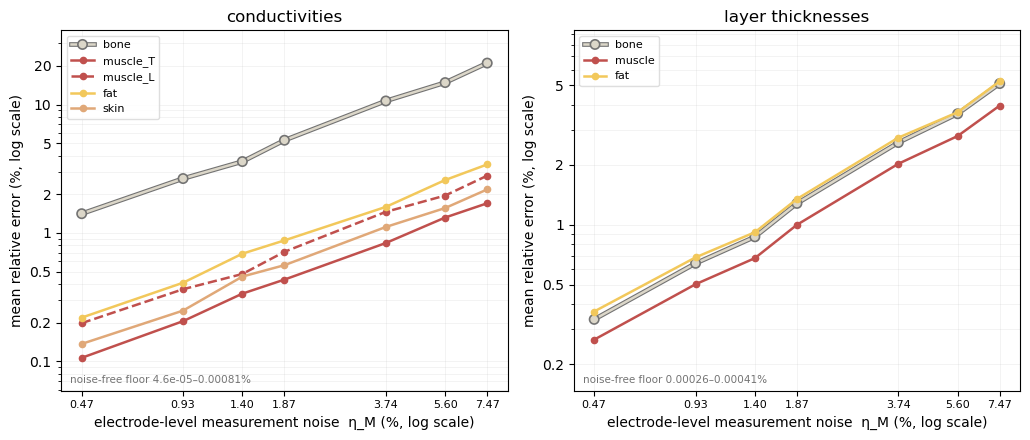

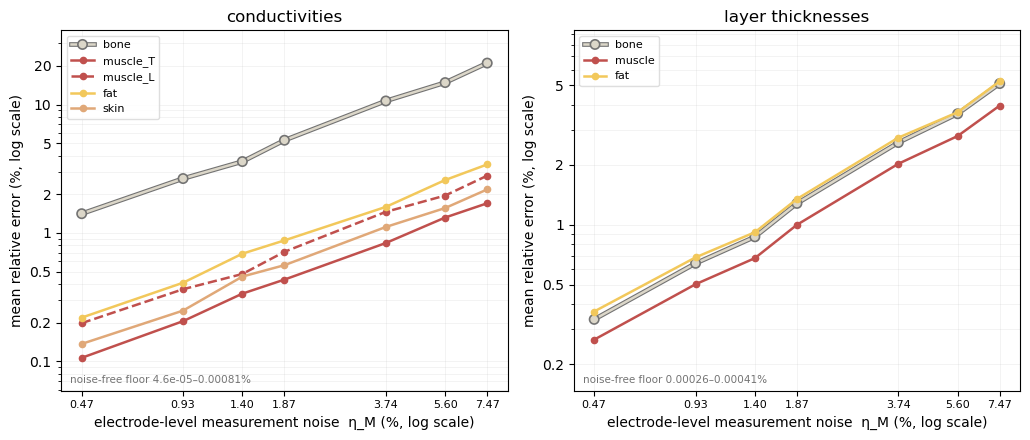

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.5))

groups = (
    (axes[0], list(parameter_names(LIMB)), range(N_SIGMA),
     [PARAM_STYLE[nm] for nm in parameter_names(LIMB)], "conductivities"),
    (axes[1], list(LIMB.layer_names[:-1]), range(N_SIGMA, len(QUANTITY_NAMES)),
     [(TISSUE_COLOURS[nm], "-") for nm in LIMB.layer_names[:-1]], "layer thicknesses"),
)

for ax, names, columns, styles, title in groups:
    columns = list(columns)
    for nm, column, (colour, ls) in zip(names, columns, styles):
        ax.plot(X_ETA, ERR[:, column], color=colour, ls=ls, lw=1.8,
                marker="o", ms=4.5, label=nm,
                path_effects=bone_effects(colour))
    style_axes(ax, title)
    set_range(ax, [ERR[:, columns]], [(FLOOR[c], styles[k][0])
                                      for k, c in enumerate(columns)])
    # placed where it collides least: the curves rise, and a fixed corner would sit
    # on one of them. Framed, because a transparent legend over a pale series is
    # unreadable in both directions
    ax.legend(fontsize=8, loc="best", framealpha=0.85, edgecolor="0.85")

fig.tight_layout()
save(fig, "conductivity-and-thickness-error-against-electrode-noise")
fig

### Average recovery error

Error bars are sample standard deviations across the five noise draws, showing variability between realisations rather than uncertainty in the mean.

saved to ./experiment-results/average-recovery-error-against-electrode-noise.png


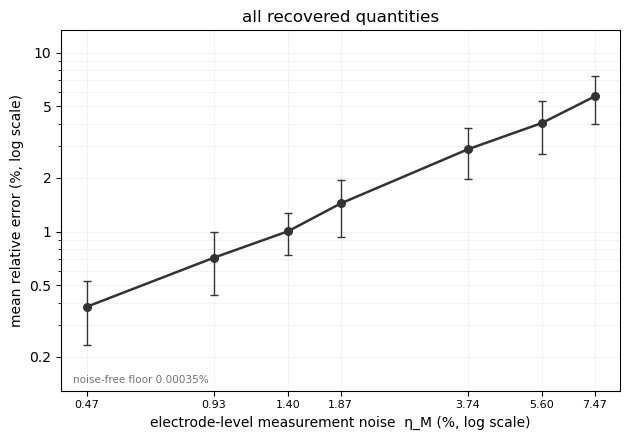

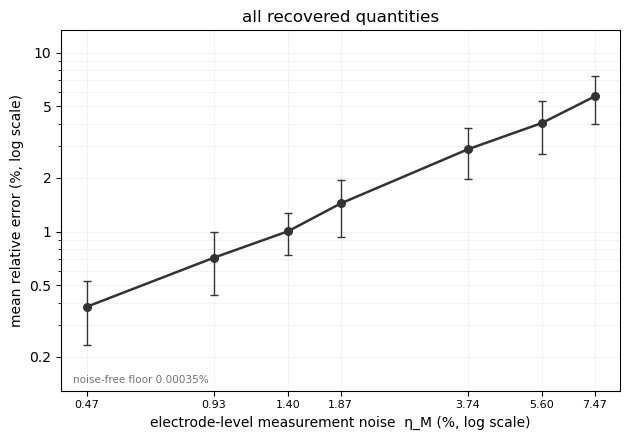

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 4.5))

ax.errorbar(X_ETA, AGGREGATE, yerr=AGGREGATE_SPREAD, color="0.2", lw=1.8,
            marker="o", ms=5.5, capsize=3, elinewidth=1.0)
style_axes(ax, "all recovered quantities")
set_range(ax, [AGGREGATE - AGGREGATE_SPREAD, AGGREGATE + AGGREGATE_SPREAD],
          [(AGGREGATE_FLOOR, "0.35")])

fig.tight_layout()
save(fig, "average-recovery-error-against-electrode-noise")
fig

### Bone recovery error

Bone is plotted separately because its error is much larger than that of the other recovered quantities.

saved to ./experiment-results/bone-recovery-error-against-electrode-noise.png


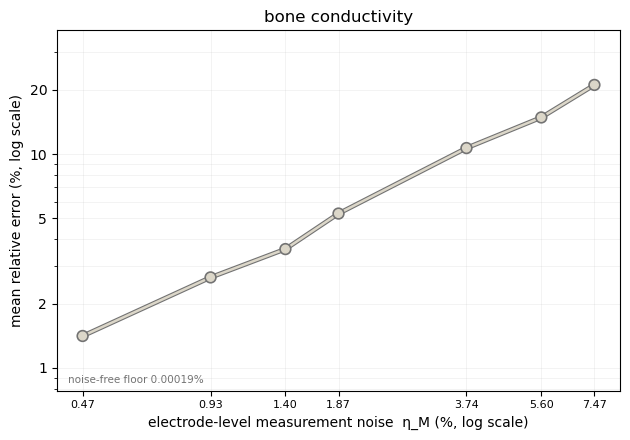

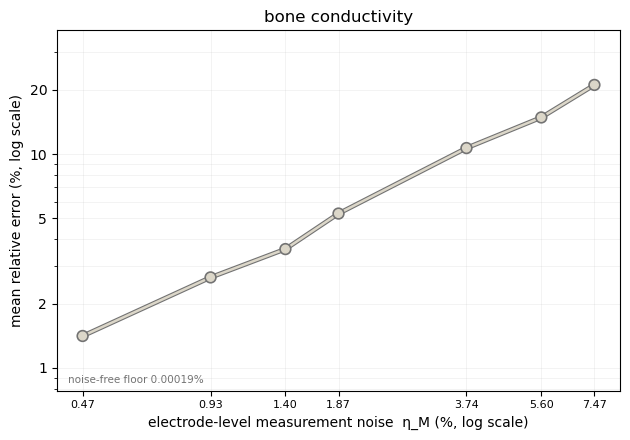

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 4.5))

colour = PARAM_STYLE["bone"][0]
ax.plot(X_ETA, ERR[:, BONE], color=colour, lw=1.8, marker="o", ms=5.5,
        path_effects=bone_effects(colour))
style_axes(ax, "bone conductivity")
set_range(ax, [ERR[:, BONE]], [(FLOOR[BONE], colour)])

fig.tight_layout()
save(fig, "bone-recovery-error-against-electrode-noise")
fig

## Generated files

The notebook writes six final-report figures to *experiment-results/*:

| File | Contents |
|---|---|
| *parameter-recovery-against-electrode-noise.png* | All quantities and levels |
| *average-parameter-recovery-against-electrode-noise.png* | Overall and group averages |
| *bone-conductivity-recovery-against-electrode-noise.png* | Bone recovery table |
| *conductivity-and-thickness-error-against-electrode-noise.png* | Conductivity and thickness errors |
| *average-recovery-error-against-electrode-noise.png* | Average recovery error |
| *bone-recovery-error-against-electrode-noise.png* | Bone recovery error |

The tables include all nine levels; the noise-trend figures include only the eight levels based on repeated noise draws.